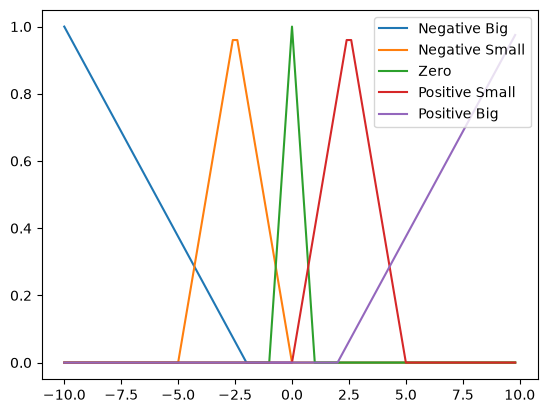

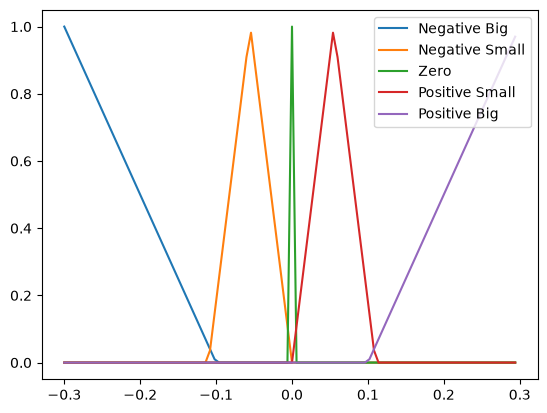

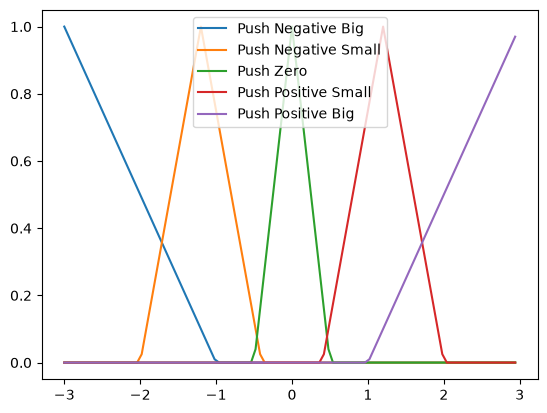

In [7]:
#
# fuzzy_position_control.py
#

import arslabrobotics as ar

class FuzzyPositionController:

    def __init__(self):
        self.NB = ar.fuzzy.Down("Negative Big", -10.0, -2.0)
        self.NS = ar.fuzzy.Triangle("Negative Small", -5.0, 0.0)
        self.ZE = ar.fuzzy.Triangle("Zero", -1, 1)
        self.PS = ar.fuzzy.Triangle("Positive Small", 0.0, 5.0)
        self.PB = ar.fuzzy.Up("Positive Big", 2.0, 10.0)
        ar.fuzzy.plot_fuzzysets([self.NB, self.NS, self.ZE, self.PS, self.PB])

        self.D_NB = ar.fuzzy.Down("Negative Big", -0.3, -0.1)
        self.D_NS = ar.fuzzy.Triangle("Negative Small", -0.11, 0.0)
        self.D_ZE = ar.fuzzy.Triangle("Zero", -0.005, 0.005)
        self.D_PS = ar.fuzzy.Triangle("Positive Small", 0.0, 0.11)
        self.D_PB = ar.fuzzy.Up("Positive Big", 0.1, 0.3)
        ar.fuzzy.plot_fuzzysets([self.D_NB, self.D_NS, self.D_ZE, self.D_PS, self.D_PB])

        self.P_NB = ar.fuzzy.Down("Push Negative Big", -3, -1)
        self.P_NS = ar.fuzzy.Triangle("Push Negative Small", -2, -0.4)
        self.P_ZE = ar.fuzzy.Triangle("Push Zero", -0.5, 0.5)
        self.P_PS = ar.fuzzy.Triangle("Push Positive Small", 0.4, 2)
        self.P_PB = ar.fuzzy.Up("Push Positive Big", 1, 3)
        ar.fuzzy.plot_fuzzysets([self.P_NB, self.P_NS, self.P_ZE, self.P_PS, self.P_PB])

        self.error = ar.fuzzy.Variable()
        self.delta_error = ar.fuzzy.Variable()
        self.push = ar.fuzzy.Variable()

        r11 = (self.delta_error(self.D_NB) & self.error(self.NB)) >> self.push(self.P_NB)
        r21 = (self.delta_error(self.D_NS) & self.error(self.NB)) >> self.push(self.P_NB)
        r31 = (self.delta_error(self.D_ZE) & self.error(self.NB)) >> self.push(self.P_NB)
        r41 = (self.delta_error(self.D_PS) & self.error(self.NB)) >> self.push(self.P_NB)
        r51 = (self.delta_error(self.D_PB) & self.error(self.NB)) >> self.push(self.P_NS)

        r12 = (self.delta_error(self.D_NB) & self.error(self.NS)) >> self.push(self.P_NB)
        r22 = (self.delta_error(self.D_NS) & self.error(self.NS)) >> self.push(self.P_NS)
        r32 = (self.delta_error(self.D_ZE) & self.error(self.NS)) >> self.push(self.P_NS)
        r42 = (self.delta_error(self.D_PS) & self.error(self.NS)) >> self.push(self.P_ZE)
        r52 = (self.delta_error(self.D_PB) & self.error(self.NS)) >> self.push(self.P_ZE)

        r13 = (self.delta_error(self.D_NB) & self.error(self.ZE)) >> self.push(self.P_NS)
        r23 = (self.delta_error(self.D_NS) & self.error(self.ZE)) >> self.push(self.P_NS)
        r33 = (self.delta_error(self.D_ZE) & self.error(self.ZE)) >> self.push(self.P_ZE)
        r43 = (self.delta_error(self.D_PS) & self.error(self.ZE)) >> self.push(self.P_PS)
        r53 = (self.delta_error(self.D_PB) & self.error(self.ZE)) >> self.push(self.P_PS)

        r14 = (self.delta_error(self.D_NB) & self.error(self.PS)) >> self.push(self.P_ZE)
        r24 = (self.delta_error(self.D_NS) & self.error(self.PS)) >> self.push(self.P_ZE)
        r34 = (self.delta_error(self.D_ZE) & self.error(self.PS)) >> self.push(self.P_PS)
        r44 = (self.delta_error(self.D_PS) & self.error(self.PS)) >> self.push(self.P_PS)
        r54 = (self.delta_error(self.D_PB) & self.error(self.PS)) >> self.push(self.P_PB)
        
        r15 = (self.delta_error(self.D_NB) & self.error(self.PB)) >> self.push(self.P_PS)
        r25 = (self.delta_error(self.D_NS) & self.error(self.PB)) >> self.push(self.P_PB)
        r35 = (self.delta_error(self.D_ZE) & self.error(self.PB)) >> self.push(self.P_PB)
        r45 = (self.delta_error(self.D_PS) & self.error(self.PB)) >> self.push(self.P_PB)
        r55 = (self.delta_error(self.D_PB) & self.error(self.PB)) >> self.push(self.P_PB)

        self.rule_set = [ r11, r12, r13, r14, r15,
                          r21, r22, r23, r24, r25,
                          r31, r32, r33, r34, r35,
                          r41, r42, r43, r44, r45,
                          r51, r52, r53, r54, r55
                        ]
        self.engine = ar.fuzzy.FuzzyEngine()
        self.engine.use_cog()

        self.output = 0
        self.prev_err = 0

    def evaluate(self, target, current):
        error = target - current
        d_error = error - self.prev_err
        self.prev_err = error
        self.error.set(error)
        self.delta_error.set(d_error)
        self.engine.execute(*self.rule_set)
        return self.engine.get(self.push)

fuzzy_ctrl = FuzzyPositionController()



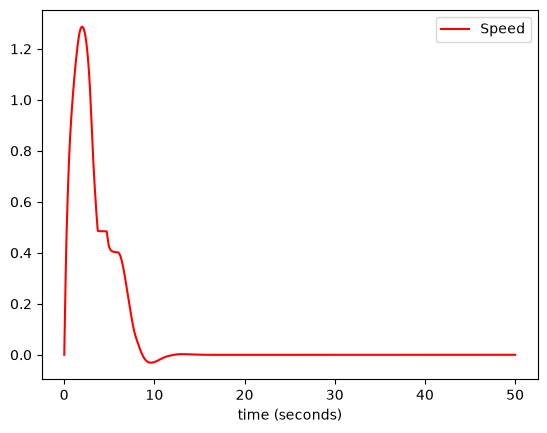

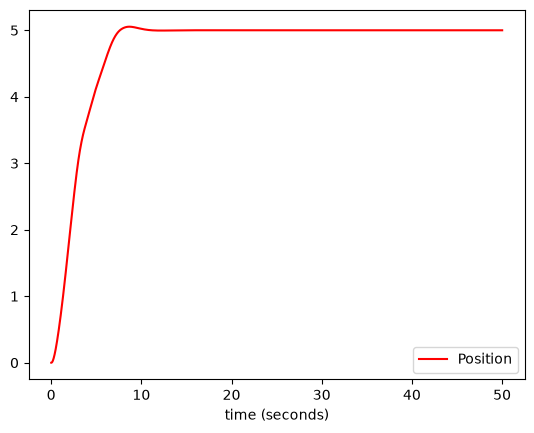

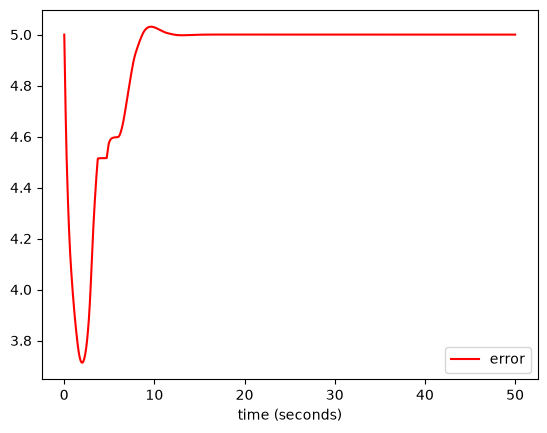

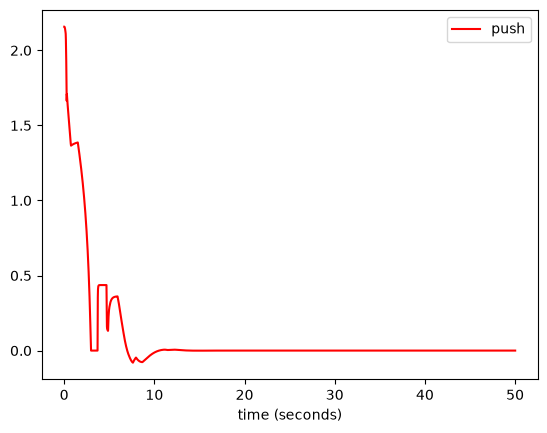

In [8]:
spd = ar.data.DataPlotter()
spd.set_x("time (seconds)")
spd.add_y("speed", "Speed")

fpd = ar.data.DataPlotter()
fpd.set_x("time (seconds)")
fpd.add_y("pos", "Position")

epd = ar.data.DataPlotter()
epd.set_x("time (seconds)")
epd.add_y("error", "error")

push_pd = ar.data.DataPlotter()
push_pd.set_x("time (seconds)")
push_pd.add_y("push", "push")


cart = ar.system.Cart(1.0, 0.9)

target = 5.0

force = 0

t = ar.utils.Time(use_fake_time = True)
t.start()
while t.get() < 50:

    t.sleep(0.01)
    delta_t = t.elapsed()

    (p, v) = cart.evaluate(delta_t, force)
    
    spd.append_x(t.get())
    spd.append_y("speed", v)
    
    fpd.append_x(t.get())
    fpd.append_y("pos", p)
    
    epd.append_x(t.get())
    epd.append_y("error", target - v)
    
    force = fuzzy_ctrl.evaluate(target, p)
    
    push_pd.append_x(t.get())
    push_pd.append_y("push", force)
    
spd.plot()
fpd.plot()
epd.plot()
push_pd.plot()
